# TraCS run analysis

Aggregates JSON traces in `output/` and reports per-model success rate, average iterations, and the breakdown of syntax vs semantic failures.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(context="paper", style="whitegrid", font_scale=1.2)
sns.set_palette("colorblind")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

OUT = Path("output")
HUMAN = OUT

## Load traces

One row per run (scenario × model × seed).

In [2]:
rows = []
iter_rows = []
for path in sorted(OUT.glob("*.json")):
    trace = json.loads(path.read_text())
    p = trace["parameters"]
    iters = trace["iterations"]
    rows.append({
        "scenario": p["scenario"],
        "model": p["coder_model"],
        "seed": p["seed"],
        "accepted": trace["accepted"],
        "n_iterations": len(iters),
        "n_syntax_fail": sum(not it["compiled"] for it in iters),
        "n_semantic_fail": sum(not it["judge_passed"] for it in iters),
    })
    for i, it in enumerate(iters, start=1):
        iter_rows.append({
            "scenario": p["scenario"],
            "model": p["coder_model"],
            "seed": p["seed"],
            "iteration": i,
            "compiled": it["compiled"],
            "judge_passed": it["judge_passed"],
        })

df = pd.DataFrame(rows)
iter_df = pd.DataFrame(iter_rows)
print(f"Loaded {len(df)} runs across {df['model'].nunique()} models and {df['scenario'].nunique()} scenarios.")
df.head()

Loaded 32 runs across 4 models and 4 scenarios.


,scenario,model,seed,accepted,n_iterations,n_syntax_fail,n_semantic_fail
0,1_halt,claude-opus-4-7,1,True,1,0,0
1,1_halt,claude-opus-4-7,2,True,1,0,0
2,1_halt,gemini-3.1-pro-preview,1,True,1,0,0
3,1_halt,gemini-3.1-pro-preview,2,True,1,0,0
4,1_halt,google/gemma-4-31B-it,1,True,1,0,0


In [3]:
def heatmap(pivot, ax, *, vmin, vmax, cmap, fmt, cbar_label):
    sns.heatmap(
        pivot, ax=ax, annot=True, fmt=fmt, cmap=cmap, vmin=vmin, vmax=vmax,
        linewidths=0.5, linecolor="white", square=False,
        cbar_kws={"label": cbar_label, "shrink": 0.8},
    )
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=20)
    ax.tick_params(axis="y", rotation=0)

## Success rate

Fraction of seeds that converged, per (model, scenario).

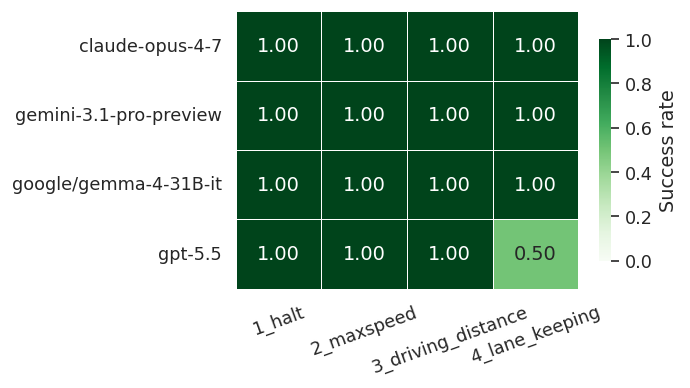

In [4]:
success_pivot = (
    df.groupby(["model", "scenario"])["accepted"].mean()
    .unstack("scenario")
)
fig, ax = plt.subplots(figsize=(1.0 + 0.9 * success_pivot.shape[1], 0.6 + 0.6 * success_pivot.shape[0]))
heatmap(success_pivot, ax, vmin=0, vmax=1, cmap="Greens", fmt=".2f", cbar_label="Success rate")
plt.show()

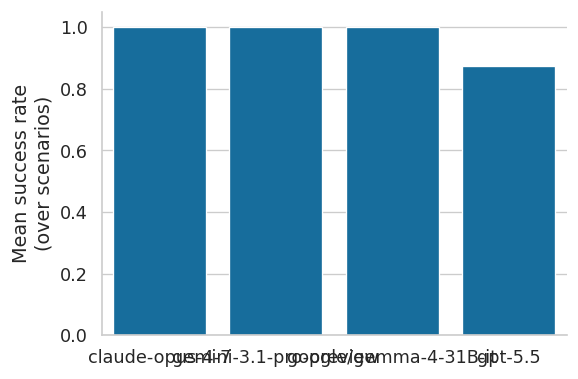

In [5]:
model_success = success_pivot.mean(axis=1).rename("mean_success_rate").reset_index()
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(data=model_success, x="model", y="mean_success_rate", ax=ax)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Mean success rate\n(over scenarios)")
ax.set_xlabel("")
plt.show()

## Iterations to convergence

Mean iteration count over seeds for successful runs only. Cells with no successes show as NaN.

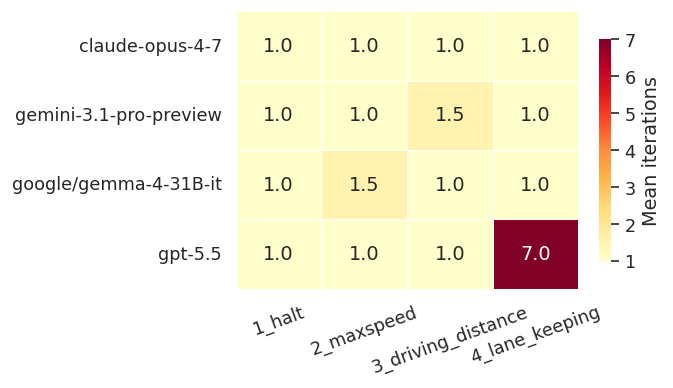

In [6]:
accepted_runs = df[df["accepted"]]
iter_pivot = (
    accepted_runs.groupby(["model", "scenario"])["n_iterations"].mean()
    .unstack("scenario")
)
vmax = max(1, iter_pivot.max().max())
fig, ax = plt.subplots(figsize=(1.0 + 0.9 * iter_pivot.shape[1], 0.6 + 0.6 * iter_pivot.shape[0]))
heatmap(iter_pivot, ax, vmin=1, vmax=vmax, cmap="YlOrRd", fmt=".1f", cbar_label="Mean iterations")
plt.show()

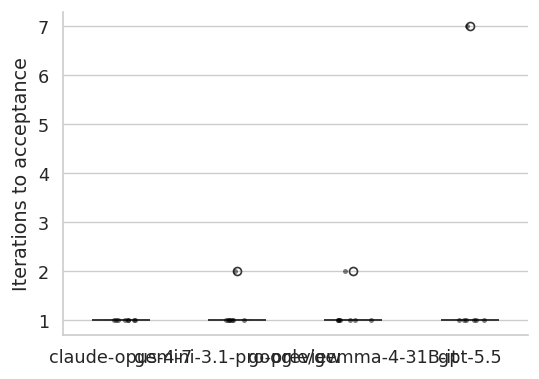

In [7]:
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.boxplot(data=accepted_runs, x="model", y="n_iterations", ax=ax, width=0.5)
sns.stripplot(data=accepted_runs, x="model", y="n_iterations", ax=ax,
              color="black", size=3, alpha=0.5, jitter=0.15)
ax.set_ylabel("Iterations to acceptance")
ax.set_xlabel("")
plt.show()

## Failure breakdown: syntax vs semantics

Fraction of iterations that failed compilation (syntax) and that were rejected by the judge (semantics). An iteration can fail on either or both.

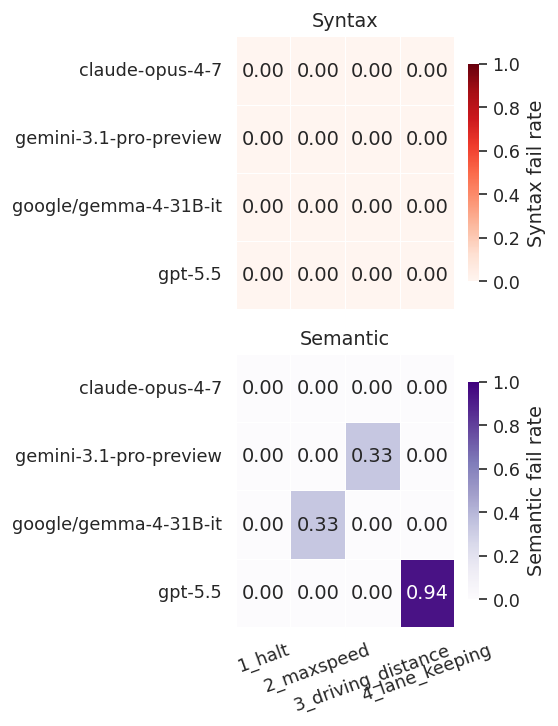

In [8]:
syntax_pivot = (
    iter_df.assign(fail=lambda d: (~d["compiled"]).astype(float))
    .groupby(["model", "scenario"])["fail"].mean()
    .unstack("scenario")
)
semantic_pivot = (
    iter_df.assign(fail=lambda d: (~d["judge_passed"]).astype(float))
    .groupby(["model", "scenario"])["fail"].mean()
    .unstack("scenario")
)

fig, axes = plt.subplots(
    2, 1,
    figsize=(1.0 + 0.9 * syntax_pivot.shape[1], 1.4 + 1.2 * syntax_pivot.shape[0]),
    sharex=True,
)
heatmap(syntax_pivot,   axes[0], vmin=0, vmax=1, cmap="Reds",    fmt=".2f", cbar_label="Syntax fail rate")
heatmap(semantic_pivot, axes[1], vmin=0, vmax=1, cmap="Purples", fmt=".2f", cbar_label="Semantic fail rate")
axes[0].set_title("Syntax")
axes[1].set_title("Semantic")
plt.tight_layout()
plt.show()

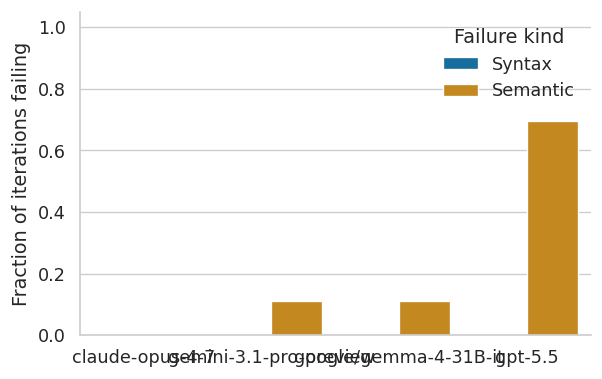

In [9]:
fail_summary = (
    iter_df.assign(
        syntax_fail=lambda d: ~d["compiled"],
        semantic_fail=lambda d: ~d["judge_passed"],
    )
    .groupby("model")[["syntax_fail", "semantic_fail"]]
    .mean()
    .reset_index()
    .melt(id_vars="model", var_name="kind", value_name="fraction")
)
fail_summary["kind"] = fail_summary["kind"].map({"syntax_fail": "Syntax", "semantic_fail": "Semantic"})

fig, ax = plt.subplots(figsize=(5.5, 3.5))
sns.barplot(data=fail_summary, x="model", y="fraction", hue="kind", ax=ax)
ax.set_ylabel("Fraction of iterations failing")
ax.set_xlabel("")
ax.set_ylim(0, 1.05)
ax.legend(title="Failure kind", frameon=False)
plt.show()

## Judge vs human agreement

Some traces have a `human_judge_passed` field per iteration. Compare it against the LLM judge's verdict and produce a confusion matrix.

In [10]:
human_rows = []
for path in sorted(HUMAN.glob("*.json")):
    trace = json.loads(path.read_text())
    p = trace["parameters"]
    for i, it in enumerate(trace["iterations"], start=1):
        if "human_judge_passed" not in it:
            continue
        human_rows.append({
            "scenario": p["scenario"],
            "model": p["coder_model"],
            "seed": p["seed"],
            "iteration": i,
            "judge_passed": it["judge_passed"],
            "human_judge_passed": it["human_judge_passed"],
        })

human_df = pd.DataFrame(human_rows)
print(f"Loaded {len(human_df)} iterations with human labels.")
agree = (human_df["judge_passed"] == human_df["human_judge_passed"]).mean()
print(f"Overall agreement: {agree:.1%}")

Loaded 49 iterations with human labels.
Overall agreement: 91.8%


In [11]:
confusion = pd.crosstab(
    human_df["human_judge_passed"].map({True: "accept", False: "reject"}),
    human_df["judge_passed"].map({True: "accept", False: "reject"}),
    rownames=["Human"], colnames=["LLM judge"],
).reindex(index=["accept", "reject"], columns=["accept", "reject"], fill_value=0)
confusion

LLM judge,accept,reject
Human,,
accept,30,3
reject,1,15


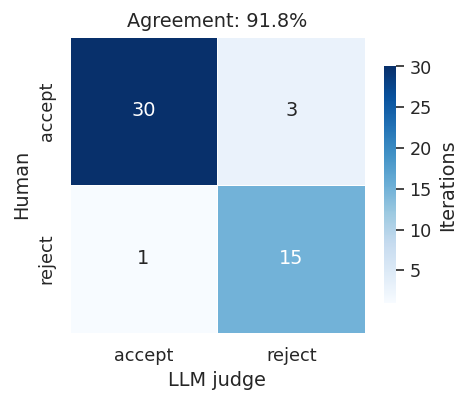

In [12]:
fig, ax = plt.subplots(figsize=(4, 3.2))
sns.heatmap(
    confusion, ax=ax, annot=True, fmt="d", cmap="Blues",
    linewidths=0.5, linecolor="white", square=True,
    cbar_kws={"label": "Iterations", "shrink": 0.8},
)
ax.set_title(f"Agreement: {agree:.1%}")
plt.show()

In [13]:
import numpy as np
from scipy import stats
from sklearn.metrics import cohen_kappa_score
from statsmodels.stats.contingency_tables import mcnemar

j = human_df["judge_passed"].astype(int).to_numpy()
h = human_df["human_judge_passed"].astype(int).to_numpy()
n = len(j)

# Cohen's kappa with Fleiss SE for 95% CI and z-test
kappa = cohen_kappa_score(h, j)
p_o = (h == j).mean()
p_h, p_j = h.mean(), j.mean()
p_e = p_h * p_j + (1 - p_h) * (1 - p_j)
se_kappa = np.sqrt(p_o * (1 - p_o) / (n * (1 - p_e) ** 2)) if p_e < 1 else float("nan")
ci_lo, ci_hi = kappa - 1.96 * se_kappa, kappa + 1.96 * se_kappa
z = kappa / se_kappa if se_kappa else float("nan")
p_kappa = 2 * (1 - stats.norm.cdf(abs(z))) if np.isfinite(z) else float("nan")

# Pearson phi (= Pearson on 0/1)
phi, p_phi = stats.pearsonr(h, j)

# Chi-square independence on the 2x2 contingency table
chi2, p_chi2, dof, _ = stats.chi2_contingency(confusion.values)

# McNemar's test for asymmetry of disagreements
mc = mcnemar(confusion.values, exact=True)

def fmt_p(p):
    return "< 0.001" if p < 0.001 else f"{p:.3g}"

print(f"Cohen's k           : {kappa:.3f}  (95% CI [{ci_lo:.2f}, {ci_hi:.2f}], p {fmt_p(p_kappa)})")
print(f"Pearson phi         : {phi:.3f}  (p {fmt_p(p_phi)})")
print(f"chi^2 independence  : chi2={chi2:.2f}, dof={dof}, p {fmt_p(p_chi2)}")
print(f"McNemar (asymmetry) : p {fmt_p(mc.pvalue)}")

Cohen's k           : 0.820  (95% CI [0.65, 0.99], p < 0.001)
Pearson phi         : 0.824  (p < 0.001)
chi^2 independence  : chi2=29.69, dof=1, p < 0.001
McNemar (asymmetry) : p 0.625


## Model characteristics overview

A radar plot summarizing each model on a [0, 1] scale. Axes, clockwise from the top:

- **Iteration syntax success rate** — fraction of iterations that compiled.
- **Iteration semantic success rate** — fraction of iterations the judge passed.
- **First-attempt success rate** — fraction of runs accepted on iteration 1 (compiled and judge-passed).
- **Recovery rate** — among runs that failed iteration 1, the fraction the loop eventually rescued. `NaN` if a model never had to recover (asterisked on the chart).
- **Final success rate** — fraction of runs eventually accepted.
- **Skipped iterations** — `(10 - a) / 9`, where `a` is the iterations an accepted run took. `1.0` means accepted on the first try, `0.0` means the full 10-iteration budget was used. Averaged over accepted runs.
- **Judge-human alignment** — agreement between the LLM judge and the human label, restricted to the model's iterations that have a human label. `NaN` if no labels exist for that model.

Axes with `NaN` values are skipped for that model.

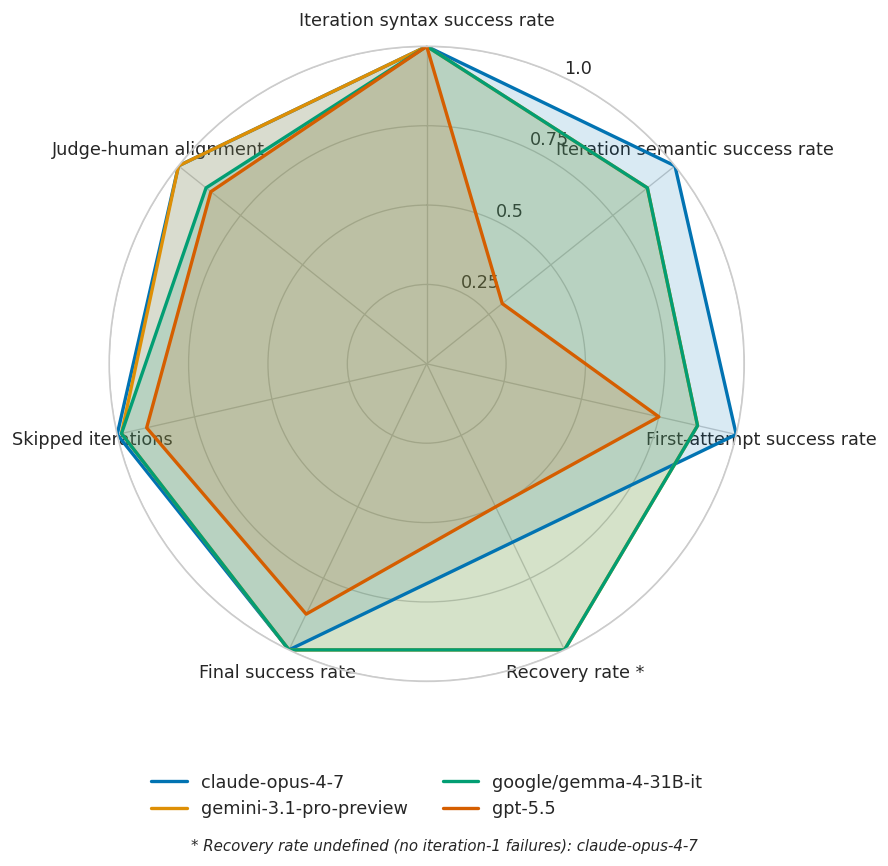

,Iteration syntax success rate,Iteration semantic success rate,First-attempt success rate,Recovery rate,Final success rate,Skipped iterations,Judge-human alignment
claude-opus-4-7,1.0,1.000,1.000,NaN,1.000,1.000,1.000
gemini-3.1-pro-preview,1.0,0.889,0.875,1.0,1.000,0.986,1.000
google/gemma-4-31B-it,1.0,0.889,0.875,1.0,1.000,0.986,0.889
gpt-5.5,1.0,0.304,0.750,0.5,0.875,0.905,0.870


In [14]:
import numpy as np

MAX_ITERATIONS = 10  # see tracs/run_all.py: --max-iterations 10
RECOVERY_LABEL = "Recovery rate"

models = sorted(df["model"].unique())

# Final success rate: outcome after all iterations of the coder/judge loop.
final_success_by_model = df.groupby("model")["accepted"].mean()

# Skipped iterations: (MAX - a) / (MAX - 1), where a is the iteration count of
# an accepted run. 1.0 when accepted on the first try, 0.0 when the full
# budget was used. Averaged over accepted runs per model.
skipped_iters_by_model = (
    df[df["accepted"]]
    .assign(skipped=lambda d: (MAX_ITERATIONS - d["n_iterations"]) / (MAX_ITERATIONS - 1))
    .groupby("model")["skipped"].mean()
)

syntax_success_by_model = (
    iter_df.assign(ok=lambda d: d["compiled"].astype(float))
    .groupby("model")["ok"].mean()
)
semantic_success_by_model = (
    iter_df.assign(ok=lambda d: d["judge_passed"].astype(float))
    .groupby("model")["ok"].mean()
)

# First-attempt success: iteration 1 both compiled and was judge-accepted.
first_attempt_by_model = (
    iter_df[iter_df["iteration"] == 1]
    .assign(ok=lambda d: (d["compiled"] & d["judge_passed"]).astype(float))
    .groupby("model")["ok"].mean()
)

# Recovery rate: of runs that did NOT pass on iteration 1, what fraction were
# eventually accepted? NaN when every run already passed on iteration 1.
first_iter_pass = (
    iter_df[iter_df["iteration"] == 1]
    .assign(first_ok=lambda d: d["compiled"] & d["judge_passed"])
    .set_index(["model", "scenario", "seed"])["first_ok"]
)
runs = df.set_index(["model", "scenario", "seed"]).join(first_iter_pass)
needed_recovery = runs[~runs["first_ok"]]
recovery_by_model = (
    needed_recovery.groupby(level="model")["accepted"].mean()
    if len(needed_recovery) else pd.Series(dtype=float)
)
recovery_by_model = pd.Series(
    {m: recovery_by_model.get(m, float("nan")) for m in models}
)

# Judge-human alignment per coder model, restricted to iterations with a label.
if len(human_df):
    alignment_by_model = (
        human_df.assign(agree=lambda d: (d["judge_passed"] == d["human_judge_passed"]).astype(float))
        .groupby("model")["agree"].mean()
    )
else:
    alignment_by_model = pd.Series(dtype=float)
alignment_by_model = pd.Series(
    {m: alignment_by_model.get(m, float("nan")) for m in models}
)

# Order, clockwise from the top.
metrics = pd.DataFrame({
    "Iteration syntax success rate": syntax_success_by_model,
    "Iteration semantic success rate": semantic_success_by_model,
    "First-attempt success rate": first_attempt_by_model,
    RECOVERY_LABEL: recovery_by_model,
    "Final success rate": final_success_by_model,
    "Skipped iterations": skipped_iters_by_model,
    "Judge-human alignment": alignment_by_model,
}).reindex(models)

# Mark the recovery axis with an asterisk if at least one model has no value.
recovery_missing = metrics[RECOVERY_LABEL].isna()
recovery_label_display = RECOVERY_LABEL + (" *" if recovery_missing.any() else "")
display_labels = [
    recovery_label_display if c == RECOVERY_LABEL else c
    for c in metrics.columns
]

angles = np.linspace(0, 2 * np.pi, len(display_labels), endpoint=False).tolist()
angles_closed = angles + angles[:1]

fig, ax = plt.subplots(figsize=(7.5, 7.5), subplot_kw={"projection": "polar"})
ax.set_theta_offset(np.pi / 2)  # 0 at the top
ax.set_theta_direction(-1)       # clockwise
palette = sns.color_palette("colorblind", n_colors=len(models))

for color, model in zip(palette, models):
    values = np.array(metrics.loc[model].tolist() + [metrics.loc[model].iloc[0]], dtype=float)
    mask = ~np.isnan(values)
    a = np.array(angles_closed)[mask]
    v = values[mask]
    if len(v) == 0:
        continue
    ax.plot(a, v, color=color, linewidth=2, label=model)
    ax.fill(a, v, color=color, alpha=0.15)

ax.set_xticks(angles)
ax.set_xticklabels(display_labels)
ax.set_yticks([0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels(["0.25", "0.5", "0.75", "1.0"])
ax.set_ylim(0, 1.0)
ax.set_rlabel_position(180 / len(display_labels))

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=min(len(models), 2),
    frameon=False,
)

if recovery_missing.any():
    missing_models = ", ".join(recovery_missing.index[recovery_missing])
    fig.text(
        0.5, 0.02,
        f"* Recovery rate undefined (no iteration-1 failures): {missing_models}",
        ha="center", va="bottom", fontsize=9, style="italic",
    )

fig.tight_layout()
plt.show()

metrics.round(3)